# Linear Quantum Repeater: Throughput vs. Number of Links

This notebook emulates a **linear quantum repeater chain** on one IBM quantum chip and measures how the
quality and the rate of end-to-end Bell pairs change as the chain gets longer: n = 1, 2, 4, 8, 16 elementary
links (2 to 32 qubits).

## Network model

```
  node:      A        1          2          3        B
  qubits:    q0 ═ q1  q2 ═ q3  q4 ═ q5  q6 ═ q7          (n = 4 links, 8 qubits)
  link:       0        1        2        3
```

- Each **elementary link** is a Bell pair |Φ+⟩ = (|00⟩ + |11⟩)/√2 made with H + CNOT on (q_{2k}, q_{2k+1}).
- End node **A** holds q0, end node **B** holds q_{2n-1}. Intermediate node j (j = 1 … n−1) holds
  q_{2j−1} and q_{2j}: its right half of link j−1 and its left half of link j.
- **Link generation** is parallel by default (all pairs at once). With `sequential=True` the pairs are made one
  at a time with barriers in between, as if a single shared source fed every link in turn.

## Nested entanglement swapping (no purification)

A **swap** at node j is a Bell-state measurement (BSM) on its two qubits: CNOT(q_{2j−1} → q_{2j}), H on q_{2j−1},
measure both. It joins link j−1 and link j into one longer link. Swaps are done in ⌈log₂ n⌉ **levels**; at level ℓ,
node j swaps if j mod 2^ℓ = 2^(ℓ−1):

```
  n = 8:  level 1: nodes 1 3 5 7   (8 links -> 4)
          level 2: nodes 2 6       (4 links -> 2)
          level 3: node  4         (2 links -> 1, end to end)
```

The BSM qubits are measured **mid-circuit** at the end of each level, with a barrier between levels, so every
level waits for the previous one's measurement results, as a real repeater waits for classical messages.

## Corrections: Pauli frame

After all swaps the end qubits hold |Φ+⟩ up to a Pauli on q_{2n−1}: the state is X^x Z^z |Φ+⟩ with
**x = XOR of all second-qubit outcomes** and **z = XOR of all first-qubit outcomes**. Instead of applying the
correction with a gate (feed-forward), each shot's measured parities are corrected in post-processing:

| basis | measured parity is multiplied by |
|---|---|
| ZZ | (−1)^x |
| XX | (−1)^z |
| YY | (−1)^(x⊕z) |

and the fidelity with |Φ+⟩ is **F = (1 + ⟨XX⟩ − ⟨YY⟩ + ⟨ZZ⟩) / 4**. F > 0.5 proves the end qubits are entangled.
With frame tracking the end nodes do not have to wait for the last swap's result before they measure, so in the
circuits here the ends are measured **in the same round as the final swap**. Part 3 (optional) compares this
with real feed-forward (`if_test`), where B must wait for the correction.

## Throughput: what is measured

Every shot delivers exactly one end-to-end pair: the swaps here never fail (a real network's links appear at
random; this emulation has no such losses). So the question is **how fast** pairs come out and **how good** they are.

| quantity | definition |
|---|---|
| cycle time T | scheduled duration of one shot (from the backend's gate and measurement times) |
| protocol rate R_proto = 1/T | pairs/s if a new attempt started the moment the last one ended |
| device rate R_dev | pairs/s actually achieved on the chip: 1 / (T + measured per-shot overhead: reset, repetition delay, electronics) |
| yield Y = 1 − H(p) | distillable ebits per pair, **lower bound** by the hashing protocol; p = Bell-state probabilities from ⟨XX⟩, ⟨YY⟩, ⟨ZZ⟩ (valid after Bell-diagonal twirling, which is free by local operations) |
| ebit rate = R × Y | throughput of **distillable** entanglement, lower bound (ebits/s) |

Y > 0 needs F ≳ 0.81 (for a Werner state); between F = 0.5 and that, pairs are entangled but hashing alone cannot
distil them (recurrence purification could, at a lower rate).

## Predictions
- Cycle time grows with the number of **levels**, not links: one round of measurements (~2.7 µs on Heron) per
  level, so T ≈ 2.7 / 2.7 / 5.5 / 8.2 / 10.9 µs for n = 1 / 2 / 4 / 8 / 16. R_proto falls only as 1/log n.
- The device rate is dominated by the repetition delay between shots (default 250 µs), so it is almost flat in n.
- Fidelity falls quickly: each swap level costs one ~2.7 µs wait for every stored qubit, plus gate and readout
  errors of all 2n qubits. Earlier runs on ibm_marrakesh: 1 swap ≈ 0.93 without waiting, ≈ 0.72 after a 4 µs wait.
  So the **ebit rate** probably drops to 0 already at n = 2–4, while pairs stay entangled (F > 0.5) up to n ≈ 4–8.
- Sequential generation adds ~0.14 µs per extra link to T (+2 µs at n = 16) and lowers F slightly.

## 0. Setup
Uses the same `.env` as the other notebooks.

In [1]:
import json
import math
import os
from collections import defaultdict
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import qiskit
import qiskit_ibm_runtime
from dotenv import load_dotenv
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
from qiskit.circuit import Clbit
from qiskit.circuit.classical import expr
from qiskit.quantum_info import Clifford, StabilizerState
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime import SamplerV2 as Sampler

print("qiskit            ", qiskit.__version__)
print("qiskit-ibm-runtime", qiskit_ibm_runtime.__version__)

qiskit             2.5.2
qiskit-ibm-runtime 0.50.0


In [2]:
load_dotenv()

N_LINKS = [1, 2, 4, 8, 16]               # elementary links; powers of 2 (qubits = 2 * links)
GEN_MODES = ["parallel", "sequential"]   # link generation: all pairs at once / one at a time (shared source)
SHOTS = 4000                             # per circuit, hardware
SIM_SHOTS = 200                          # per circuit, ideal simulation (shot by shot, so kept small)
BACKEND_NAME = os.getenv("IBM_BACKEND") or None
EXCLUDE_QUBITS = [137]                   # physical qubits never to use (137 read 1 in 83% of shots on 2026-10-16)
READOUT_LIMIT = 0.08                     # readout scan: never use qubits whose readout error is above this right now
STORE_US = 8.0                           # typical storage time of a qubit here, weighs T2 in the line choice

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

BASES = ["XX", "YY", "ZZ"]
FRAME_LABELS = {"00": "Φ+", "10": "Ψ+", "01": "Φ-", "11": "Ψ-"}  # key = x z: state of the ends before correction

n_circuits = len(GEN_MODES) * len(N_LINKS) * len(BASES)
print(f"{n_circuits} circuits in one job, {n_circuits * SHOTS:,} shots, largest chain = {2 * max(N_LINKS)} qubits")

30 circuits in one job, 120,000 shots, largest chain = 32 qubits


## 1. Build the circuits

Register layout: `bsm[2(j−1)]` = first-qubit outcome (q_{2j−1}) and `bsm[2(j−1)+1]` = second-qubit outcome (q_{2j})
of the swap at node j; `out[0]` = q0, `out[1]` = q_{2n−1}. With n = 1 there is no swap and no `bsm` register.

`feedforward=True` (Part 3) adds, after the last level, `if_test` blocks that apply X on q_{2n−1} if x = 1 and Z if
z = 1 (x, z computed on the control hardware as XOR expressions), and only then measures the ends.

 1 links: swap levels = []
 2 links: swap levels = [[1]]
 4 links: swap levels = [[1, 3], [2]]
 8 links: swap levels = [[1, 3, 5, 7], [2, 6], [4]]
16 links: swap levels = [[1, 3, 5, 7, 9, 11, 13, 15], [2, 6, 10, 14], [4, 12], [8]]


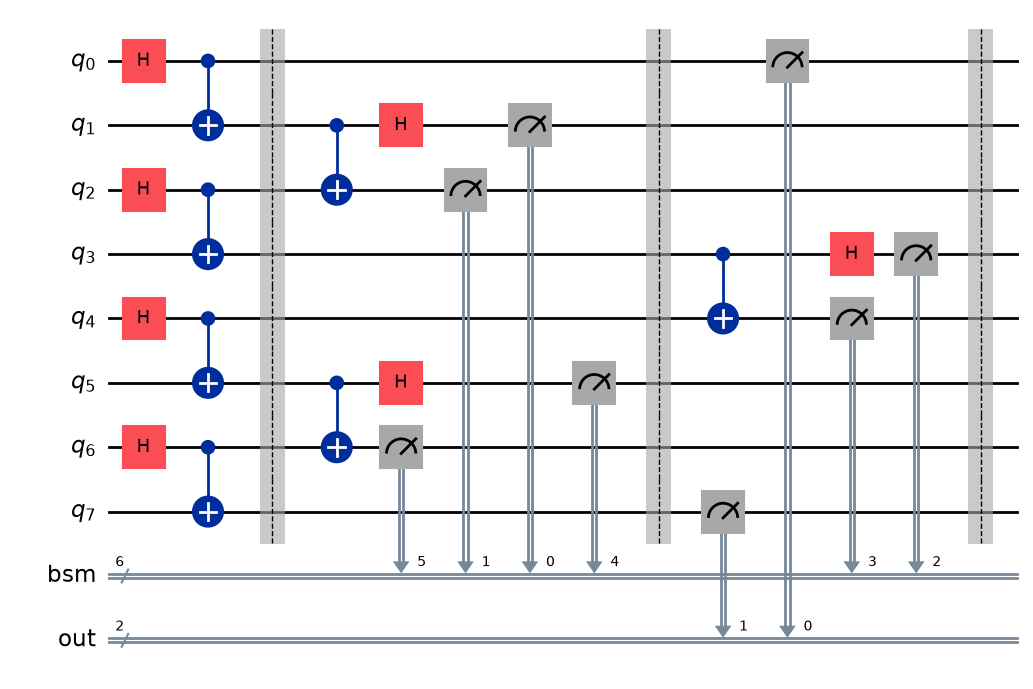

In [3]:
def swap_levels(n_links):
    # List of levels; each level is the list of nodes j (1 ... n_links-1) that swap in parallel at that level.
    assert n_links & (n_links - 1) == 0, "nested swapping needs a power-of-2 number of links"
    levels, level = [], 1
    while 2 ** (level - 1) < n_links:
        levels.append([j for j in range(1, n_links) if j % 2**level == 2 ** (level - 1)])
        level += 1
    return levels


def add_basis_rotation(qc, pauli, qubit):
    # Rotate so that a Z-measurement measures the requested Pauli.
    if pauli == "X":
        qc.h(qubit)
    elif pauli == "Y":
        qc.sdg(qubit)
        qc.h(qubit)


def xor_all(bits):
    # Classical expression: XOR of a list of clbits (evaluated on the control hardware)
    e = expr.lift(bits[0])
    for b in bits[1:]:
        e = expr.bit_xor(e, b)
    return e


def build_repeater(n_links, basis, sequential=False, feedforward=False):
    n_qubits = 2 * n_links
    last = n_qubits - 1
    q = QuantumRegister(n_qubits, "q")
    out = ClassicalRegister(2, "out")
    bsm = ClassicalRegister(2 * (n_links - 1), "bsm") if n_links > 1 else None
    qc = QuantumCircuit(*[r for r in (q, bsm, out) if r is not None],
                        name=f"rep{n_links}_{'seq' if sequential else 'par'}{'_ff' if feedforward else ''}_{basis}")

    # Link generation
    for k in range(n_links):
        qc.h(2 * k)
        qc.cx(2 * k, 2 * k + 1)
        if sequential and k < n_links - 1:
            qc.barrier()                       # next link only after this one is made
    qc.barrier()

    def measure_ends():
        add_basis_rotation(qc, basis[0], 0)
        add_basis_rotation(qc, basis[1], last)
        qc.measure(0, out[0])
        qc.measure(last, out[1])

    levels = swap_levels(n_links)
    for i, nodes in enumerate(levels):
        for j in nodes:                        # Bell measurements of this level, in parallel
            qc.cx(2 * j - 1, 2 * j)
            qc.h(2 * j - 1)
        for j in nodes:
            qc.measure(2 * j - 1, bsm[2 * (j - 1)])
            qc.measure(2 * j, bsm[2 * (j - 1) + 1])
        if i == len(levels) - 1 and not feedforward:
            measure_ends()                     # Pauli frame: the ends need not wait for the last result
        qc.barrier()                           # next level starts only after this one is measured

    if feedforward and n_links > 1:
        with qc.if_test(xor_all(bsm[1::2])):  # x = XOR of all second-qubit outcomes
            qc.x(last)
        with qc.if_test(xor_all(bsm[0::2])):  # z = XOR of all first-qubit outcomes
            qc.z(last)
    if feedforward or n_links == 1:
        measure_ends()
    return qc


for n in N_LINKS:
    print(f"{n:>2} links: swap levels = {swap_levels(n)}")

build_repeater(4, "ZZ").draw("mpl", fold=-1)

In [4]:
def make_circuits(modes=GEN_MODES, feedforward=False):
    circs, labs = [], []
    for mode in modes:
        for n in N_LINKS:
            for b in BASES:
                circs.append(build_repeater(n, b, sequential=(mode == "sequential"), feedforward=feedforward))
                labs.append((mode, n, b))
    return circs, labs


circuits, labels = make_circuits()

## 2. Analysis helpers

Results are handled as `{register name: list of bitstrings}`, both from the hardware and from the simulator.
`joint_counts` turns them into counts keyed `"xz ab"`: x and z are the frame parities of the shot, a = q0 and
b = q_{2n−1} (Qiskit bitstrings are little-endian; they are reversed so that keys read left to right).

The three corrected correlators also give the full **Bell-diagonal** picture: the probabilities of the four
Bell states, p(Φ+) = F, p(Φ−) = (1 − ⟨XX⟩ + ⟨YY⟩ + ⟨ZZ⟩)/4, p(Ψ+) = (1 + ⟨XX⟩ + ⟨YY⟩ − ⟨ZZ⟩)/4,
p(Ψ−) = (1 − ⟨XX⟩ − ⟨YY⟩ − ⟨ZZ⟩)/4. Their entropy H(p) sets the hashing yield Y = 1 − H(p).

In [5]:
FRAME_SIGN = {  # basis -> function(x, z) -> ±1, undoes X^x Z^z on the last qubit
    "XX": lambda x, z: (-1) ** z,
    "YY": lambda x, z: (-1) ** (x ^ z),
    "ZZ": lambda x, z: (-1) ** x,
}
BELL_CORRELATORS = {
    "Φ+": {"XX": 1, "YY": -1, "ZZ": 1},
    "Φ-": {"XX": -1, "YY": 1, "ZZ": 1},
    "Ψ+": {"XX": 1, "YY": 1, "ZZ": -1},
    "Ψ-": {"XX": -1, "YY": -1, "ZZ": -1},
}


def pub_strings(pub_result):
    # Sampler pub result -> {register name: list of bitstrings}, same format as stabilizer_sample()
    return {name: reg.get_bitstrings() for name, reg in pub_result.data.items()}


def joint_counts(strings):
    # {"xz ab": count}; x = XOR of all second-qubit (m2) bits, z = XOR of all first-qubit (m1) bits
    out = strings["out"]
    bsm = strings.get("bsm") or [""] * len(out)
    counts = defaultdict(int)
    for s_bsm, s_out in zip(bsm, out, strict=True):
        bits = s_bsm[::-1]                     # little-endian -> bits[i] = bsm[i]
        z = bits[0::2].count("1") % 2
        x = bits[1::2].count("1") % 2
        counts[f"{x}{z} {s_out[::-1]}"] += 1
    return dict(counts)


def _correlator(samples):
    # samples: list of (±1, count) -> (mean, standard error)
    n = sum(c for _, c in samples)
    if n == 0:
        return float("nan"), float("nan")
    mean = sum(v * c for v, c in samples) / n
    return mean, np.sqrt(max(1 - mean**2, 0) / n)


def _fidelity(corr, target):
    f = (1 + sum(target[b] * corr[b][0] for b in BASES)) / 4
    err = np.sqrt(sum(corr[b][1] ** 2 for b in BASES)) / 4
    return f, err


def bell_probs(xx, yy, zz):
    # Bell-diagonal probabilities [Φ+, Φ-, Ψ+, Ψ-] from the three correlators (clipped against shot noise)
    p = np.array([1 + xx - yy + zz, 1 - xx + yy + zz, 1 + xx + yy - zz, 1 - xx - yy - zz]) / 4
    p = np.clip(p, 0, None)
    return p / p.sum()


def hashing_yield(xx, yy, zz):
    # Distillable ebits per pair, lower bound: max(0, 1 - H(p)) (hashing protocol on the Bell-diagonal twirl)
    p = bell_probs(xx, yy, zz)
    p = p[p > 0]
    return max(0.0, 1 + float(np.sum(p * np.log2(p))))


def analyze(counts_by_basis, frame_correction=True, mc_samples=2000):
    # counts_by_basis: {"XX": joint_counts, "YY": ..., "ZZ": ...}
    per_frame = {k: {} for k in FRAME_LABELS}
    corrected, uncorrected = {}, {}
    for basis in BASES:
        groups = {k: [] for k in FRAME_LABELS}
        all_corr, all_raw = [], []
        for key, n in counts_by_basis[basis].items():
            xz, ab = key.split()
            parity = 1 if ab[0] == ab[1] else -1
            sign = FRAME_SIGN[basis](int(xz[0]), int(xz[1])) if frame_correction else 1
            groups[xz].append((parity, n))
            all_raw.append((parity, n))
            all_corr.append((sign * parity, n))
        for xz in FRAME_LABELS:
            per_frame[xz][basis] = _correlator(groups[xz])
        corrected[basis] = _correlator(all_corr)
        uncorrected[basis] = _correlator(all_raw)

    f, err = _fidelity(corrected, BELL_CORRELATORS["Φ+"])
    xx, yy, zz = (corrected[b][0] for b in BASES)
    rng = np.random.default_rng(1234)          # yield error: Monte Carlo over the correlator errors
    draws = [hashing_yield(*(rng.normal(corrected[b][0], corrected[b][1]) for b in BASES)) for _ in range(mc_samples)]
    expected = {xz: BELL_CORRELATORS[lab if frame_correction else "Φ+"] for xz, lab in FRAME_LABELS.items()}
    return {
        "F": f,
        "err": err,
        "F_uncorrected": _fidelity(uncorrected, BELL_CORRELATORS["Φ+"])[0],
        "correlators": {b: corrected[b][0] for b in BASES},
        "bell_probs": dict(zip(["Φ+", "Φ-", "Ψ+", "Ψ-"], bell_probs(xx, yy, zz).tolist())),
        "yield": hashing_yield(xx, yy, zz),
        "yield_err": float(np.std(draws)),
        # fidelity of each frame's sub-ensemble with the state it should be in (Φ+ for all if corrected by gates)
        "per_frame": {f"{FRAME_LABELS[xz]} ({xz})": _fidelity(per_frame[xz], expected[xz])[0] for xz in FRAME_LABELS
                      if not np.isnan(per_frame[xz]["ZZ"][0])},
    }


def analyze_all(strings_list, run_labels, frame_correction=True):
    # list of {register: bitstrings} + matching labels -> ({mode: {n: summary}}, {mode: {n: {basis: counts}}})
    grouped = defaultdict(lambda: defaultdict(dict))
    for strings, (mode, n, b) in zip(strings_list, run_labels, strict=True):
        grouped[mode][n][b] = joint_counts(strings)
    summaries = {m: {n: analyze(c, frame_correction) for n, c in by_n.items()} for m, by_n in grouped.items()}
    counts = {m: {n: dict(c) for n, c in by_n.items()} for m, by_n in grouped.items()}
    return summaries, counts


def print_fidelity_table(title, summaries):
    print(title)
    print(f"  {'mode':<11} {'links':>5} {'qubits':>6}   {'F':>13}   {'F uncorr.':>9}   {'<XX>':>6} {'<YY>':>6} {'<ZZ>':>6}   {'yield':>13}")
    for mode, by_n in summaries.items():
        for n, s in sorted(by_n.items()):
            c = s["correlators"]
            print(f"  {mode:<11} {n:>5} {2 * n:>6}   {s['F']:.3f} ± {s['err']:.3f}   {s['F_uncorrected']:>9.3f}   "
                  f"{c['XX']:+.3f} {c['YY']:+.3f} {c['ZZ']:+.3f}   {s['yield']:.3f} ± {s['yield_err']:.3f}")

## 3. Ideal simulator for mid-circuit measurements

`StatevectorSampler` cannot do mid-circuit measurements and needs memory 2^qubits (32 qubits is out of reach),
and Qiskit Aer is not installed. Every circuit here is a **Clifford** circuit (H, S, CNOT, Paulis, measurements),
so it can be simulated exactly with stabilizer states, shot by shot: gates between measurements are merged into
one Clifford, each measurement draws a random outcome with the right probability and collapses the state, and
`if_test` conditions are evaluated on the bits measured so far. This works for the logical circuits and for the
transpiled hardware (ISA) circuits alike (rz by multiples of π/2, sx, x, cz are Clifford too).

In [6]:
SIM_SKIP = {"barrier", "delay"}


def _cond_value(cond, bits):
    # Evaluate an if_test condition (clbit / register comparison or classical expression) on measured bits
    if isinstance(cond, tuple):
        target, val = cond
        if isinstance(target, Clbit):
            return bits[target] == val
        return sum(bits[b] << i for i, b in enumerate(target)) == val
    if isinstance(cond, expr.Var):
        return bool(bits[cond.var])
    if isinstance(cond, expr.Value):
        return bool(cond.value)
    if isinstance(cond, expr.Cast):
        return _cond_value(cond.operand, bits)
    if isinstance(cond, expr.Unary):
        return not _cond_value(cond.operand, bits)
    if isinstance(cond, expr.Binary):
        a, b = _cond_value(cond.left, bits), _cond_value(cond.right, bits)
        op = expr.Binary.Op
        return {op.BIT_XOR: a != b, op.NOT_EQUAL: a != b, op.EQUAL: a == b, op.BIT_AND: a and b,
                op.LOGIC_AND: a and b, op.BIT_OR: a or b, op.LOGIC_OR: a or b}[cond.op]
    raise TypeError(f"unsupported condition {cond!r}")


def _compile(block, qmap, cmap, n):
    # Circuit -> list of steps ("gates", Clifford) / ("measure", qubits, clbits) / ("if", cond, cmap, branches)
    steps, seg = [], QuantumCircuit(n)

    def flush():
        nonlocal seg
        if seg.size():
            steps.append(("gates", Clifford(seg)))
            seg = QuantumCircuit(n)

    for inst in block.data:
        op = inst.operation
        if op.name in SIM_SKIP:
            continue
        qs = [qmap[x] for x in inst.qubits]
        if op.name == "measure":
            flush()
            if steps and steps[-1][0] == "measure":   # consecutive measurements: one step
                steps[-1][1].append(qs[0])
                steps[-1][2].append(cmap[inst.clbits[0]])
            else:
                steps.append(("measure", qs, [cmap[inst.clbits[0]]]))
        elif op.name == "if_else":
            flush()
            branches = []
            for body in op.blocks:
                bq = {bb: qmap[ob] for bb, ob in zip(body.qubits, inst.qubits)}
                bc = {bb: cmap[ob] for bb, ob in zip(body.clbits, inst.clbits)}
                branches.append(_compile(body, bq, bc, n))
            steps.append(("if", op.condition, cmap, branches))
        else:
            seg.append(op, qs)
    flush()
    return steps


def _run(steps, state, bits, rng):
    for step in steps:
        if step[0] == "gates":
            state = state.evolve(step[1])
        elif step[0] == "measure":
            state.seed(int(rng.integers(2**63)))   # fresh seed each time: a state's RNG is copied with the state
            outcome, state = state.measure(step[1])
            for clbit, ch in zip(step[2], reversed(outcome)):
                bits[clbit] = int(ch)
        else:
            _, cond, cmap, branches = step
            if _cond_value(cond, {c: bits[cmap[c]] for c in cmap}):
                state = _run(branches[0], state, bits, rng)
            elif len(branches) > 1:
                state = _run(branches[1], state, bits, rng)
    return state


def stabilizer_sample(qc, shots, seed=1234):
    # Ideal shot-by-shot simulation -> {register name: list of bitstrings}; only qubits that are used are simulated
    active = sorted({qc.find_bit(x).index for inst in qc.data if inst.operation.name not in SIM_SKIP
                     for x in inst.qubits})
    qmap = {qc.qubits[p]: i for i, p in enumerate(active)}
    steps = _compile(qc, qmap, {c: c for c in qc.clbits}, len(active))
    init = StabilizerState(QuantumCircuit(len(active)))
    rng = np.random.default_rng(seed)
    data = {cr.name: [] for cr in qc.cregs}
    for _ in range(shots):
        bits = {c: 0 for c in qc.clbits}
        _run(steps, init, bits, rng)
        for cr in qc.cregs:
            data[cr.name].append("".join(str(bits[b]) for b in reversed(cr)))
    return data


def ideal_check(circs, labs, shots, frame_correction=True, title="IDEAL SIMULATION"):
    # Simulate, print the table, and stop if any F is not ≈ 1 (then the frame logic is wrong)
    strings = [stabilizer_sample(qc, shots, seed=i) for i, qc in enumerate(circs)]
    summaries, _ = analyze_all(strings, labs, frame_correction)
    print_fidelity_table(title, summaries)
    bad = [(m, n, s["F"]) for m, by_n in summaries.items() for n, s in by_n.items() if s["F"] < 0.99]
    if bad:
        raise RuntimeError(f"Ideal F is not ≈ 1 for {bad}: fix the circuit / frame logic before using hardware")
    print("  OK: F ≈ 1 for every chain")
    return summaries

## Part 1: Ideal simulation (sanity check)

Every chain must give **F = 1** after frame correction. The column *F uncorr.* shows what happens without the
correction: ≈ 0.25 (no correlation left) for every chain with a swap, 1 for n = 1 (no swap, nothing to correct).
This proves the correction is doing the work. Takes about a minute (shot by shot, up to 32 qubits).

In [7]:
sim_summaries = ideal_check(circuits, labels, SIM_SHOTS)

IDEAL SIMULATION
  mode        links qubits               F   F uncorr.     <XX>   <YY>   <ZZ>           yield
  parallel        1      2   1.000 ± 0.000       1.000   +1.000 -1.000 +1.000   1.000 ± 0.000
  parallel        2      4   1.000 ± 0.000       0.255   +1.000 -1.000 +1.000   1.000 ± 0.000
  parallel        4      8   1.000 ± 0.000       0.242   +1.000 -1.000 +1.000   1.000 ± 0.000
  parallel        8     16   1.000 ± 0.000       0.223   +1.000 -1.000 +1.000   1.000 ± 0.000
  parallel       16     32   1.000 ± 0.000       0.302   +1.000 -1.000 +1.000   1.000 ± 0.000
  sequential      1      2   1.000 ± 0.000       1.000   +1.000 -1.000 +1.000   1.000 ± 0.000
  sequential      2      4   1.000 ± 0.000       0.280   +1.000 -1.000 +1.000   1.000 ± 0.000
  sequential      4      8   1.000 ± 0.000       0.217   +1.000 -1.000 +1.000   1.000 ± 0.000
  sequential      8     16   1.000 ± 0.000       0.220   +1.000 -1.000 +1.000   1.000 ± 0.000
  sequential     16     32   1.000 ± 0.000 

## Part 2: Run on IBM Quantum hardware

### 2a. Connect

In [8]:
token = os.getenv("QISKIT_IBM_TOKEN")
if not token:
    raise RuntimeError("QISKIT_IBM_TOKEN not found — create a .env file (see .env.example)")

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=token,
    instance=os.getenv("QISKIT_IBM_INSTANCE") or None,
)
n_needed = 2 * max(N_LINKS)
if BACKEND_NAME:
    backend = service.backend(BACKEND_NAME)
else:
    backend = service.least_busy(operational=True, simulator=False, min_num_qubits=n_needed)

REP_DELAY = getattr(backend.configuration(), "default_rep_delay", None)   # seconds, waited between shots
print(f"Backend: {backend.name}  ({backend.num_qubits} qubits)  pending jobs: {backend.status().pending_jobs}")
print(f"Default repetition delay: {REP_DELAY * 1e6:.0f} µs" if REP_DELAY else "Default repetition delay: unknown")

qiskit_runtime_service._discover_account:WARNING:2026-10-20 16:03:29,694: Loading account with the given token. A saved account will not be used.


Backend: ibm_marrakesh  (156 qubits)  pending jobs: 1
Default repetition delay: 250 µs


### 2b. Choose the line of qubits

The chain needs 2n physically adjacent qubits in a line, so every link gate and every swap acts on neighbours.
As in the nested notebook, the line is chosen from **live** readout data, because calibration data can be stale
(qubit 137 read 1 in 83% of shots on 2026-10-16 while the calibration said 2.3% readout error):

1. **Readout scan** of the whole chip: one small job (all qubits 0, then all 1, 1000 shots each). Qubits above
   `READOUT_LIMIT` and those in `EXCLUDE_QUBITS` are never used.
2. **Best line**: branch-and-bound search over all simple paths for the lowest cost
   Σ −ln(1 − live readout error) + Σ −ln(1 − CZ error) + Σ `STORE_US`/T2.
3. If no clean line is long enough for the longest chain, that chain is dropped (16 → 8 → …).

In [9]:
def readout_scan(shots=1000):
    # Readout error of every qubit right now: prepare all 0, then all 1, and count wrong answers
    qubits = [q for q in range(backend.num_qubits) if backend.target["measure"].get((q,)) is not None]
    n = len(qubits)
    all0 = QuantumCircuit(n)
    all0.measure_all()
    all1 = QuantumCircuit(n)
    all1.x(range(n))
    all1.measure_all()
    pm = generate_preset_pass_manager(backend=backend, optimization_level=1, initial_layout=qubits)
    res = Sampler(mode=backend).run(pm.run([all0, all1]), shots=shots).result()
    p1_given0 = np.array([[int(c) for c in s[::-1]] for s in res[0].data.meas.get_bitstrings()]).mean(axis=0)
    p0_given1 = 1 - np.array([[int(c) for c in s[::-1]] for s in res[1].data.meas.get_bitstrings()]).mean(axis=0)
    return {qubits[i]: float((p1_given0[i] + p0_given1[i]) / 2) for i in range(n)}


def choose_line(n_qubits, exclude, readout):
    # Lowest-cost simple path of n_qubits physical qubits (branch and bound over the coupling graph)
    t = backend.target
    q_cost = {}
    for q, ro in readout.items():
        props = t.qubit_properties[q] if t.qubit_properties else None
        if q in exclude or props is None or not props.t2:
            continue
        q_cost[q] = -math.log(1 - min(ro, 0.5)) + STORE_US * 1e-6 / props.t2
    e_cost, adj = {}, {q: [] for q in q_cost}
    for (a, b), props in t["cz"].items():
        if a in q_cost and b in q_cost and props is not None and props.error is not None:
            e_cost[frozenset((a, b))] = -math.log(1 - min(props.error, 0.5))
            if b not in adj[a]:
                adj[a].append(b)
                adj[b].append(a)
    if not e_cost:
        return None, math.inf
    floor = min(q_cost.values()) + min(e_cost.values())
    best = [math.inf, None]

    def extend(path, seen, cost):
        if len(path) == n_qubits:
            if cost < best[0]:
                best[:] = [cost, list(path)]
            return
        if cost + (n_qubits - len(path)) * floor >= best[0]:
            return
        last = path[-1]
        options = sorted((e_cost[frozenset((last, nb))] + q_cost[nb], nb) for nb in adj[last] if nb not in seen)
        for step, nb in options:
            path.append(nb)
            seen.add(nb)
            extend(path, seen, cost + step)
            path.pop()
            seen.discard(nb)

    for start in sorted(q_cost, key=q_cost.get):
        extend([start], {start}, q_cost[start])
    return best[1], best[0]


READOUT_SCAN = readout_scan()
bad = {q: e for q, e in READOUT_SCAN.items() if e > READOUT_LIMIT}
excluded = set(EXCLUDE_QUBITS) | set(bad)
errs = np.array(list(READOUT_SCAN.values()))
print(f"Readout scan of {len(READOUT_SCAN)} qubits: median error {np.median(errs):.3f}, "
      f"{len(bad)} above {READOUT_LIMIT:.0%}")
if bad:
    print("  not used:", ", ".join(f"{q} ({e:.0%})" for q, e in sorted(bad.items(), key=lambda x: -x[1])))

LINE = None
while N_LINKS:
    LINE, line_cost = choose_line(2 * max(N_LINKS), excluded, READOUT_SCAN)
    if LINE is not None:
        break
    print(f"No clean line of {2 * max(N_LINKS)} qubits: dropping the {max(N_LINKS)}-link chain")
    N_LINKS = N_LINKS[:-1]
if LINE is None:
    raise RuntimeError("No clean line found even for the shortest chain; try another backend or later")

circuits, labels = make_circuits()   # rebuild in case N_LINKS changed
print(f"\nChains: {N_LINKS} links -> {len(circuits)} circuits, {len(circuits) * SHOTS:,} shots")
print("Physical qubit line:", LINE)
print("readout error now  :", " ".join(f"{READOUT_SCAN[q]:.3f}" for q in LINE))

C:\Users\LOQ\AppData\Local\Temp\ipykernel_9476\583860577.py:11: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  res = Sampler(mode=backend).run(pm.run([all0, all1]), shots=shots).result()


Readout scan of 156 qubits: median error 0.016, 23 above 8%
  not used: 130 (50%), 82 (50%), 118 (45%), 11 (44%), 94 (42%), 81 (36%), 31 (35%), 1 (32%), 119 (26%), 83 (25%), 29 (23%), 113 (21%), 43 (17%), 125 (16%), 144 (14%), 9 (13%), 5 (13%), 39 (13%), 44 (9%), 64 (9%), 65 (9%), 92 (9%), 59 (9%)

Chains: [1, 2, 4, 8, 16] links -> 30 circuits, 120,000 shots
Physical qubit line: [105, 106, 107, 108, 109, 110, 111, 98, 91, 90, 89, 78, 69, 70, 71, 58, 51, 50, 49, 48, 47, 46, 45, 37, 25, 24, 23, 22, 21, 36, 41, 42]
readout error now  : 0.008 0.019 0.024 0.004 0.024 0.008 0.018 0.012 0.008 0.017 0.056 0.008 0.039 0.022 0.014 0.027 0.045 0.022 0.046 0.056 0.008 0.022 0.016 0.059 0.011 0.026 0.076 0.016 0.004 0.027 0.014 0.008


### 2c. Transpile and check

Every chain uses the start of the line from 2b (`initial_layout`), so all chains and both generation modes share
the same physical qubits. Three checks run on every transpiled circuit before anything is submitted:

1. **No SWAPs:** exactly 2n − 1 two-qubit gates (n link gates + n − 1 swaps), each between neighbours on the line.
2. **Still correct:** the transpiled circuits (all 30, as they will run) are simulated ideally and must give F ≈ 1.
3. **Timing:** the scheduled duration of one shot (cycle time T) from the backend's gate and measurement times.

In [10]:
def check_no_swaps(isa, n_links, line):
    # Exactly 2n-1 two-qubit gates, all between neighbours on the line -> no routing SWAPs were inserted
    pos = {p: i for i, p in enumerate(line)}
    pairs = [tuple(isa.find_bit(x).index for x in inst.qubits) for inst in isa.data
             if inst.operation.num_qubits == 2 and inst.operation.name != "barrier"]
    problems = []
    if "swap" in isa.count_ops():
        problems.append("contains SWAP gates")
    if len(pairs) != 2 * n_links - 1:
        problems.append(f"{len(pairs)} two-qubit gates, expected {2 * n_links - 1}")
    far = [p for p in pairs if abs(pos.get(p[0], -9) - pos.get(p[1], 9)) != 1]
    if far:
        problems.append(f"gates between non-neighbours on the line: {far}")
    return problems


def cycle_time(isa):
    # Scheduled duration of one shot (s). if_else blocks are counted as their body (correction applied); the
    # classical feed-forward latency of the hardware comes on top and is not included.
    flat = isa.copy_empty_like()
    for inst in isa.data:
        if inst.operation.name == "if_else":
            body = inst.operation.blocks[0]
            flat.compose(body, qubits=inst.qubits, clbits=inst.clbits if body.num_clbits else None, inplace=True)
        else:
            flat.append(inst)
    return flat.estimate_duration(backend.target, unit="s")


def transpile_and_check(circs, labs):
    isa_list, times = [], {}
    for qc, (mode, n, b) in zip(circs, labs, strict=True):
        pm = generate_preset_pass_manager(backend=backend, optimization_level=3,
                                          initial_layout=LINE[:qc.num_qubits], seed_transpiler=1234)
        isa = pm.run(qc)
        problems = check_no_swaps(isa, n, LINE)
        if problems:
            raise RuntimeError(f"{mode} {n} links {b}: " + "; ".join(problems))
        isa_list.append(isa)
        times.setdefault(mode, {}).setdefault(n, []).append(cycle_time(isa))
    # cycle time per chain: the three bases differ only by single-qubit gates; take the longest
    return isa_list, {m: {n: max(ts) for n, ts in by_n.items()} for m, by_n in times.items()}


isa_circuits, CYCLE_TIME = transpile_and_check(circuits, labels)
print(f"No SWAPs: all {len(isa_circuits)} circuits have 2n-1 two-qubit gates between line neighbours\n")
isa_sim_summaries = ideal_check(isa_circuits, labels, SIM_SHOTS // 2, title="IDEAL SIMULATION OF THE ISA CIRCUITS")

over = REP_DELAY or 0.0
print(f"\nExpected timing ({'repetition delay ' + format(over * 1e6, '.0f') + ' µs' if REP_DELAY else 'no delay known'} "
      f"used as per-shot overhead until it is measured):")
print(f"  {'mode':<11} {'links':>5} {'levels':>6}   {'T (µs)':>7}   {'R_proto (kHz)':>13}   {'R_dev (kHz)':>11}")
for mode, by_n in CYCLE_TIME.items():
    for n, T in sorted(by_n.items()):
        print(f"  {mode:<11} {n:>5} {len(swap_levels(n)):>6}   {T * 1e6:>7.2f}   {1e-3 / T:>13.1f}   {1e-3 / (T + over):>11.2f}")

No SWAPs: all 30 circuits have 2n-1 two-qubit gates between line neighbours

IDEAL SIMULATION OF THE ISA CIRCUITS
  mode        links qubits               F   F uncorr.     <XX>   <YY>   <ZZ>           yield
  parallel        1      2   1.000 ± 0.000       1.000   +1.000 -1.000 +1.000   1.000 ± 0.000
  parallel        2      4   1.000 ± 0.000       0.300   +1.000 -1.000 +1.000   1.000 ± 0.000
  parallel        4      8   1.000 ± 0.000       0.250   +1.000 -1.000 +1.000   1.000 ± 0.000
  parallel        8     16   1.000 ± 0.000       0.240   +1.000 -1.000 +1.000   1.000 ± 0.000
  parallel       16     32   1.000 ± 0.000       0.270   +1.000 -1.000 +1.000   1.000 ± 0.000
  sequential      1      2   1.000 ± 0.000       1.000   +1.000 -1.000 +1.000   1.000 ± 0.000
  sequential      2      4   1.000 ± 0.000       0.260   +1.000 -1.000 +1.000   1.000 ± 0.000
  sequential      4      8   1.000 ± 0.000       0.205   +1.000 -1.000 +1.000   1.000 ± 0.000
  sequential      8     16   1.000 ± 0.0

### 2d. Submit
Both generation modes and all chain lengths go in **one** job, so they run on the same calibration.

In [11]:
sampler = Sampler(mode=backend)
job = sampler.run(isa_circuits, shots=SHOTS)
JOB_ID = job.job_id()

run_stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
(RESULTS_DIR / f"{run_stamp}_{backend.name}_repeater_job.txt").write_text(JOB_ID, encoding="utf-8")
print("Submitted job", JOB_ID, "on", backend.name)
print("Track it at https://quantum.cloud.ibm.com/workloads")

C:\Users\LOQ\AppData\Local\Temp\ipykernel_9476\397143815.py:1: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


Submitted job dbbuaq424mrc73cies10 on ibm_marrakesh
Track it at https://quantum.cloud.ibm.com/workloads


### 2e. (Optional) Retrieve a previous job
Run sections 0–3 and 2a (with the same settings as the original job, so `labels` match), then this cell instead
of 2b, 2c and 2d. `CYCLE_TIME` is recomputed from the transpiled circuits (no hardware time is used).

In [12]:
# JOB_ID = "paste-job-id-here"
# job = service.job(JOB_ID)
# backend = job.backend()
# LINE = [...]                  # copy "physical_qubit_line" from the matching *_repeater_results.json
# READOUT_SCAN, excluded = None, set(EXCLUDE_QUBITS)
# isa_circuits, CYCLE_TIME = transpile_and_check(circuits, labels)
# run_stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")

### 2f. Fidelity

In [13]:
hw_result = job.result()
hw_strings = [pub_strings(r) for r in hw_result]
hw_summaries, hw_counts = analyze_all(hw_strings, labels)
print_fidelity_table(f"HARDWARE ({backend.name})", hw_summaries)

print("\nPer-frame fidelity (each frame sub-ensemble vs. the Bell state it should be in, before correction):")
for mode, by_n in hw_summaries.items():
    for n, s in sorted(by_n.items()):
        print(f"  {mode:<11} {n:>2} links: " + "  ".join(f"{k} {v:.3f}" for k, v in s["per_frame"].items()))

HARDWARE (ibm_marrakesh)
  mode        links qubits               F   F uncorr.     <XX>   <YY>   <ZZ>           yield
  parallel        1      2   0.943 ± 0.003       0.943   +0.930 -0.912 +0.930   0.598 ± 0.014
  parallel        2      4   0.883 ± 0.004       0.251   +0.852 -0.815 +0.865   0.300 ± 0.016
  parallel        4      8   0.555 ± 0.006       0.251   +0.310 -0.267 +0.644   0.000 ± 0.000
  parallel        8     16   0.351 ± 0.007       0.257   +0.065 -0.021 +0.317   0.000 ± 0.000
  parallel       16     32   0.260 ± 0.007       0.255   -0.007 +0.019 +0.068   0.000 ± 0.000
  sequential      1      2   0.940 ± 0.003       0.940   +0.927 -0.914 +0.916   0.576 ± 0.015
  sequential      2      4   0.905 ± 0.003       0.259   +0.895 -0.863 +0.864   0.403 ± 0.016
  sequential      4      8   0.549 ± 0.006       0.252   +0.304 -0.266 +0.626   0.000 ± 0.000
  sequential      8     16   0.347 ± 0.007       0.259   +0.047 -0.041 +0.299   0.000 ± 0.000
  sequential     16     32   0.262 

### 2g. Throughput

The per-shot overhead (reset, repetition delay, control electronics) is measured from the job's **execution
spans**: total execution time / total shots − mean cycle time. It is the same for every circuit, so the device
rate of each chain is R_dev = 1 / (T + overhead).

In [14]:
def measured_overhead(result, cycle_times):
    # Average wall-clock time per shot from the execution spans, minus the mean scheduled cycle time
    spans = result.metadata.get("execution", {}).get("execution_spans")
    if not spans:
        return None, None
    total = sum(span.duration for span in spans)
    shots = sum(span.size for span in spans)
    t_shot = total / shots
    return t_shot - float(np.mean(cycle_times)), t_shot


def throughput_table(summaries, cycle, overhead):
    rows = {}
    for mode, by_n in summaries.items():
        for n, s in sorted(by_n.items()):
            T = cycle[mode][n]
            r_proto, r_dev = 1 / T, 1 / (T + overhead)
            rows.setdefault(mode, {})[n] = {
                "levels": len(swap_levels(n)), "T_us": T * 1e6,
                "F": s["F"], "F_err": s["err"], "entangled": bool(s["F"] - 2 * s["err"] > 0.5),
                "yield": s["yield"], "yield_err": s["yield_err"],
                "R_proto": r_proto, "R_dev": r_dev,
                "ebit_rate_proto": r_proto * s["yield"], "ebit_rate_dev": r_dev * s["yield"],
            }
    return rows


def print_throughput(rows):
    print(f"  {'mode':<11} {'links':>5} {'T (µs)':>7} {'F':>7} {'ent.':>5} {'yield':>6}   "
          f"{'R_proto':>9} {'ebit_proto':>10}   {'R_dev':>7} {'ebit_dev':>8}   (pairs/s, ebits/s)")
    for mode, by_n in rows.items():
        for n, r in sorted(by_n.items()):
            print(f"  {mode:<11} {n:>5} {r['T_us']:>7.2f} {r['F']:>7.3f} {'yes' if r['entangled'] else 'no':>5} "
                  f"{r['yield']:>6.3f}   {r['R_proto']:>9.0f} {r['ebit_rate_proto']:>10.0f}   "
                  f"{r['R_dev']:>7.0f} {r['ebit_rate_dev']:>8.0f}")


all_cycle = [CYCLE_TIME[m][n] for (m, n, b) in labels]
OVERHEAD, T_SHOT = measured_overhead(hw_result, all_cycle)
if OVERHEAD is None:
    OVERHEAD = REP_DELAY or 0.0
    print(f"No execution spans in the result: using the repetition delay {OVERHEAD * 1e6:.0f} µs as overhead")
else:
    print(f"Measured: {T_SHOT * 1e6:.1f} µs per shot on average -> overhead {OVERHEAD * 1e6:.1f} µs per shot "
          f"(repetition delay setting: {REP_DELAY * 1e6 if REP_DELAY else float('nan'):.0f} µs)")
THROUGHPUT = throughput_table(hw_summaries, CYCLE_TIME, OVERHEAD)
print()
print_throughput(THROUGHPUT)

Measured: 283.2 µs per shot on average -> overhead 276.5 µs per shot (repetition delay setting: 250 µs)

  mode        links  T (µs)       F  ent.  yield     R_proto ebit_proto     R_dev ebit_dev   (pairs/s, ebits/s)
  parallel        1    2.86   0.943   yes  0.598      349650     209016      3580     2140
  parallel        2    2.96   0.883   yes  0.300      337382     101254      3578     1074
  parallel        4    5.79   0.555   yes  0.000      172771          0      3543        0
  parallel        8    8.62   0.351    no  0.000      115955          0      3507        0
  parallel       16   11.46   0.260    no  0.000       87230          0      3473        0
  sequential      1    2.86   0.940   yes  0.576      349650     201480      3580     2063
  sequential      2    3.10   0.905   yes  0.403      322165     129738      3577     1440
  sequential      4    6.21   0.549   yes  0.000      161082          0      3537        0
  sequential      8    9.62   0.347    no  0.000      1

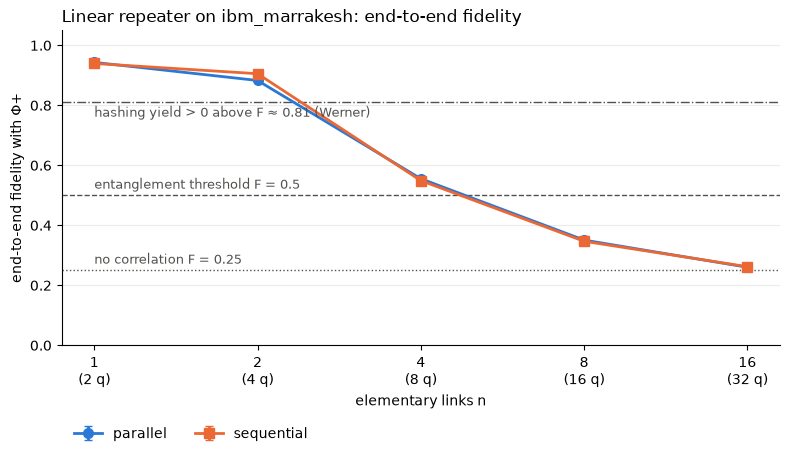

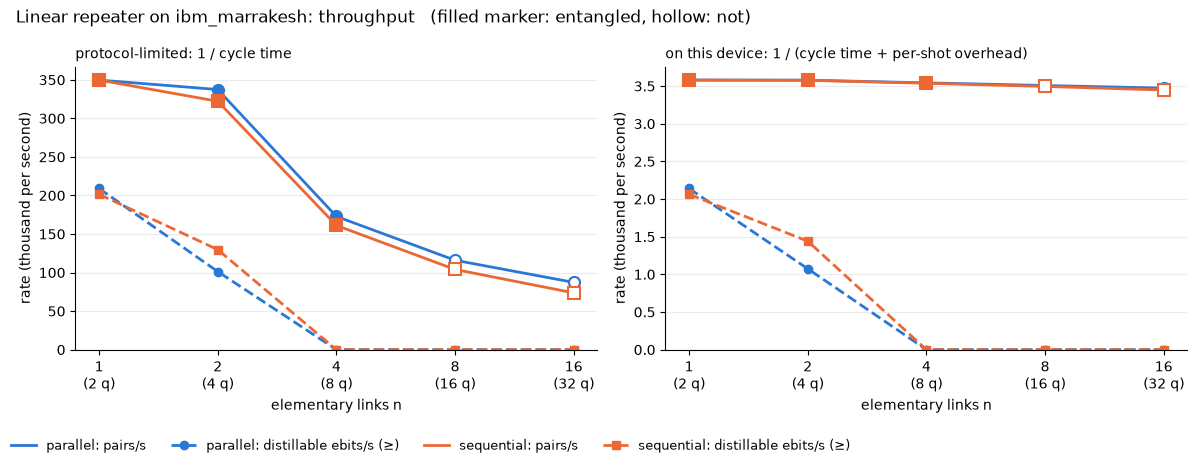

In [15]:
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]   # categorical slots 1-3, fixed order (parallel, sequential, ff)
SERIES_MARKERS = ["o", "s", "D"]
INK = "#52514e"
HASHING_F = 0.8107                                     # Werner-state fidelity where the hashing yield reaches 0


def _style(ax, ns):
    ax.set_xscale("log", base=2)
    ax.set_xticks(ns, [f"{n}\n({2 * n} q)" for n in ns])
    ax.minorticks_off()
    ax.set_xlabel("elementary links n")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)


def plot_fidelity(summaries, title):
    fig, ax = plt.subplots(figsize=(8, 4.8))
    ns = sorted({n for by_n in summaries.values() for n in by_n})
    for (mode, by_n), color, marker in zip(summaries.items(), SERIES_COLORS, SERIES_MARKERS):
        xs = sorted(by_n)
        ax.errorbar(xs, [by_n[n]["F"] for n in xs], yerr=[by_n[n]["err"] for n in xs], color=color, marker=marker,
                    markersize=7, linewidth=2, capsize=3, label=mode)
    for y, text, style, va in ((HASHING_F, "hashing yield > 0 above F ≈ 0.81 (Werner)", "-.", "top"),
                               (0.5, "entanglement threshold F = 0.5", "--", "bottom"),
                               (0.25, "no correlation F = 0.25", ":", "bottom")):
        ax.axhline(y, color=INK, linestyle=style, linewidth=1)
        ax.text(ns[0], y + (0.012 if va == "bottom" else -0.012), text, ha="left", va=va, color=INK, fontsize=9)
    _style(ax, ns)
    ax.set_ylabel("end-to-end fidelity with Φ+")
    ax.set_ylim(0, 1.05)
    ax.set_title(title, loc="left")
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.22), ncol=3)
    fig.tight_layout()
    return fig


def plot_throughput(rows, title):
    # Two panels with their own scale: protocol-limited (1/T) and as achieved on the device (1/(T + overhead))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    ns = sorted({n for by_n in rows.values() for n in by_n})
    for ax, key, sub in ((axes[0], "proto", "protocol-limited: 1 / cycle time"),
                         (axes[1], "dev", "on this device: 1 / (cycle time + per-shot overhead)")):
        for (mode, by_n), color, marker in zip(rows.items(), SERIES_COLORS, SERIES_MARKERS):
            xs = sorted(by_n)
            pairs = [by_n[n][f"R_{key}"] / 1e3 for n in xs]
            ebits = [by_n[n][f"ebit_rate_{key}"] / 1e3 for n in xs]
            ax.plot(xs, pairs, color=color, linewidth=2, label=f"{mode}: pairs/s")
            for n, y in zip(xs, pairs):   # filled marker = entangled pair (F > 0.5 by 2 SE), hollow = not
                ent = by_n[n]["entangled"]
                ax.plot(n, y, marker=marker, markersize=8, color=color, markerfacecolor=color if ent else "white",
                        markeredgewidth=1.5, linestyle="none")
            ax.plot(xs, ebits, color=color, linewidth=2, linestyle="--", marker=marker, markersize=6,
                    label=f"{mode}: distillable ebits/s (≥)")
        _style(ax, ns)
        ax.set_ylim(bottom=0)
        ax.set_ylabel("rate (thousand per second)")
        ax.set_title(sub, loc="left", fontsize=10)
    handles, texts = axes[0].get_legend_handles_labels()
    fig.legend(handles, texts, frameon=False, loc="lower left", ncol=len(rows) * 2, fontsize=9)
    fig.suptitle(title + "   (filled marker: entangled, hollow: not)", x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0.07, 1, 1))
    return fig


fig = plot_fidelity(hw_summaries, f"Linear repeater on {backend.name}: end-to-end fidelity")
fig.savefig(RESULTS_DIR / f"{run_stamp}_{backend.name}_repeater_fidelity.png", dpi=150)
fig = plot_throughput(THROUGHPUT, f"Linear repeater on {backend.name}: throughput")
fig.savefig(RESULTS_DIR / f"{run_stamp}_{backend.name}_repeater_throughput.png", dpi=150)

### 2h. Per-qubit check

Every measured qubit here should read 1 in about **50%** of shots (each is half of an entangled pair or a random
Bell-measurement bit). A qubit far from 50% was misbehaving during the job, like qubit 137 on 2026-10-16.

In [16]:
def qubit_p1(strings, n_links):
    # P(measured 1) for each chain position 0 ... 2*n_links-1
    out = np.array([[int(c) for c in s[::-1]] for s in strings["out"]])
    nq = 2 * n_links
    p = {0: out[:, 0].mean(), nq - 1: out[:, 1].mean()}
    if n_links > 1:
        bsm = np.array([[int(c) for c in s[::-1]] for s in strings["bsm"]])
        for j in range(1, n_links):
            p[2 * j - 1] = bsm[:, 2 * (j - 1)].mean()
            p[2 * j] = bsm[:, 2 * (j - 1) + 1].mean()
    return p


QUBIT_P1_WORST = {}   # physical qubit -> P(1) furthest from 0.5 over all circuits
for strings, (mode, n, b) in zip(hw_strings, labels):
    for pos, p in qubit_p1(strings, n).items():
        q = LINE[pos]
        if q not in QUBIT_P1_WORST or abs(p - 0.5) > abs(QUBIT_P1_WORST[q] - 0.5):
            QUBIT_P1_WORST[q] = float(p)

suspects = {q: p for q, p in QUBIT_P1_WORST.items() if abs(p - 0.5) > 0.10}
print("Worst P(1) per qubit:", " ".join(f"{q}:{QUBIT_P1_WORST[q]:.2f}" for q in LINE if q in QUBIT_P1_WORST))
print("Suspicious qubits:", suspects or "none")

Worst P(1) per qubit: 105:0.45 106:0.49 107:0.48 108:0.47 109:0.48 110:0.49 111:0.46 98:0.48 91:0.48 90:0.47 89:0.52 78:0.52 69:0.47 70:0.45 71:0.47 58:0.39 51:0.47 50:0.48 49:0.46 48:0.46 47:0.49 46:0.49 45:0.51 37:0.52 25:0.48 24:0.51 23:0.55 22:0.49 21:0.51 36:0.48 41:0.49 42:0.46
Suspicious qubits: {58: 0.3855}


In [17]:
try:
    usage = job.metrics().get("usage", {})
except Exception as exc:   # metrics are informational only
    usage = {"error": str(exc)}

record = {
    "experiment": "linear_repeater_throughput",
    "timestamp_utc": run_stamp,
    "backend": backend.name,
    "job_id": JOB_ID,
    "shots_per_circuit": SHOTS,
    "n_links": N_LINKS,
    "gen_modes": GEN_MODES,
    "physical_qubit_line": LINE,
    "excluded_qubits": sorted(excluded),
    "readout_limit": READOUT_LIMIT,
    "readout_scan": READOUT_SCAN,
    "qubit_p1_worst": QUBIT_P1_WORST,
    "rep_delay_s": REP_DELAY,
    "measured_time_per_shot_s": T_SHOT,
    "overhead_per_shot_s": OVERHEAD,
    "usage": usage,
    "cycle_time_s": {m: {str(n): t for n, t in by_n.items()} for m, by_n in CYCLE_TIME.items()},
    "throughput": {m: {str(n): r for n, r in by_n.items()} for m, by_n in THROUGHPUT.items()},
    "qiskit": qiskit.__version__,
    "qiskit_ibm_runtime": qiskit_ibm_runtime.__version__,
    # counts keyed "xz ab": frame parities x, z of the shot, then q0 and the last qubit
    "counts": {m: {str(n): c for n, c in by_n.items()} for m, by_n in hw_counts.items()},
    "summary": {m: {str(n): s for n, s in by_n.items()} for m, by_n in hw_summaries.items()},
}
path = RESULTS_DIR / f"{run_stamp}_{backend.name}_repeater_results.json"
path.write_text(json.dumps(record, indent=2, ensure_ascii=False), encoding="utf-8")
print("Saved", path)

print("\nLog lines for CLAUDE.md:")
for mode, by_n in THROUGHPUT.items():
    for n, r in sorted(by_n.items()):
        print(f"| {run_stamp} | {backend.name} | {JOB_ID} | repeater {mode}, {n} links ({2 * n} q) | {SHOTS} "
              f"| {r['F']:.3f} ± {r['F_err']:.3f} | - | T {r['T_us']:.1f} µs, yield {r['yield']:.3f}, "
              f"R_dev {r['R_dev']:.0f}/s, ebit_dev {r['ebit_rate_dev']:.0f}/s |")

Saved results\20261020T220425Z_ibm_marrakesh_repeater_results.json

Log lines for CLAUDE.md:
| 20261020T220425Z | ibm_marrakesh | dbbuaq424mrc73cies10 | repeater parallel, 1 links (2 q) | 4000 | 0.943 ± 0.003 | - | T 2.9 µs, yield 0.598, R_dev 3580/s, ebit_dev 2140/s |
| 20261020T220425Z | ibm_marrakesh | dbbuaq424mrc73cies10 | repeater parallel, 2 links (4 q) | 4000 | 0.883 ± 0.004 | - | T 3.0 µs, yield 0.300, R_dev 3578/s, ebit_dev 1074/s |
| 20261020T220425Z | ibm_marrakesh | dbbuaq424mrc73cies10 | repeater parallel, 4 links (8 q) | 4000 | 0.555 ± 0.006 | - | T 5.8 µs, yield 0.000, R_dev 3543/s, ebit_dev 0/s |
| 20261020T220425Z | ibm_marrakesh | dbbuaq424mrc73cies10 | repeater parallel, 8 links (16 q) | 4000 | 0.351 ± 0.007 | - | T 8.6 µs, yield 0.000, R_dev 3507/s, ebit_dev 0/s |
| 20261020T220425Z | ibm_marrakesh | dbbuaq424mrc73cies10 | repeater parallel, 16 links (32 q) | 4000 | 0.260 ± 0.007 | - | T 11.5 µs, yield 0.000, R_dev 3473/s, ebit_dev 0/s |
| 20261020T220425Z | ibm_ma

## Part 3 (optional): Real-time feed-forward instead of the Pauli frame

Here the correction is applied **on the chip**: after the last level, the control hardware computes x and z (XOR of
the measured bits) and applies X and/or Z on q_{2n−1} with `if_test`; only then are the ends measured. No
post-processing correction is used (the raw parities must already be right).

Compared with the Pauli frame this costs time: the ends wait one more measurement round plus the classical
decision latency, so expect lower F and a longer cycle time. It runs as a **separate job** (parallel generation
only, 15 circuits), so a problem with dynamic circuits cannot spoil Part 2. Needs sections 0–3, 2a and 2b.

In [18]:
ff_circuits, ff_labels = make_circuits(modes=["parallel"], feedforward=True)
ff_labels = [("feedforward", n, b) for (_, n, b) in ff_labels]
ff_sim = ideal_check(ff_circuits, ff_labels, SIM_SHOTS, frame_correction=False, title="IDEAL SIMULATION, FEED-FORWARD")
ff_isa, ff_cycle = transpile_and_check(ff_circuits, ff_labels)
ideal_check(ff_isa, ff_labels, SIM_SHOTS // 2, frame_correction=False, title="IDEAL SIMULATION, FEED-FORWARD ISA")
print("\nCycle time without the feed-forward latency (µs):",
      ", ".join(f"{n}: {t * 1e6:.2f}" for n, t in sorted(ff_cycle["feedforward"].items())))

IDEAL SIMULATION, FEED-FORWARD
  mode        links qubits               F   F uncorr.     <XX>   <YY>   <ZZ>           yield
  feedforward     1      2   1.000 ± 0.000       1.000   +1.000 -1.000 +1.000   1.000 ± 0.000
  feedforward     2      4   1.000 ± 0.000       1.000   +1.000 -1.000 +1.000   1.000 ± 0.000
  feedforward     4      8   1.000 ± 0.000       1.000   +1.000 -1.000 +1.000   1.000 ± 0.000
  feedforward     8     16   1.000 ± 0.000       1.000   +1.000 -1.000 +1.000   1.000 ± 0.000
  feedforward    16     32   1.000 ± 0.000       1.000   +1.000 -1.000 +1.000   1.000 ± 0.000
  OK: F ≈ 1 for every chain
IDEAL SIMULATION, FEED-FORWARD ISA
  mode        links qubits               F   F uncorr.     <XX>   <YY>   <ZZ>           yield
  feedforward     1      2   1.000 ± 0.000       1.000   +1.000 -1.000 +1.000   1.000 ± 0.000
  feedforward     2      4   1.000 ± 0.000       1.000   +1.000 -1.000 +1.000   1.000 ± 0.000
  feedforward     4      8   1.000 ± 0.000       1.000   +1.

In [19]:
ff_job = Sampler(mode=backend).run(ff_isa, shots=SHOTS)
FF_JOB_ID = ff_job.job_id()
ff_stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
(RESULTS_DIR / f"{ff_stamp}_{backend.name}_repeater_ff_job.txt").write_text(FF_JOB_ID, encoding="utf-8")
print("Submitted feed-forward job", FF_JOB_ID)

C:\Users\LOQ\AppData\Local\Temp\ipykernel_9476\2289195058.py:1: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  ff_job = Sampler(mode=backend).run(ff_isa, shots=SHOTS)


Submitted feed-forward job dbbubj1gv2cc73e95qlg


HARDWARE (ibm_marrakesh), FEED-FORWARD (no post-processing correction)
  mode        links qubits               F   F uncorr.     <XX>   <YY>   <ZZ>           yield
  feedforward     1      2   0.939 ± 0.003       0.939   +0.934 -0.914 +0.908   0.575 ± 0.015
  feedforward     2      4   0.655 ± 0.006       0.655   +0.439 -0.432 +0.750   0.000 ± 0.000
  feedforward     4      8   0.510 ± 0.006       0.510   +0.253 -0.213 +0.573   0.000 ± 0.000
  feedforward     8     16   0.323 ± 0.007       0.323   +0.031 -0.026 +0.236   0.000 ± 0.000
  feedforward    16     32   0.263 ± 0.007       0.263   +0.004 +0.011 +0.057   0.000 ± 0.000

Measured time per shot: feed-forward 295.5 µs vs Pauli-frame job 283.2 µs
  mode        links  T (µs)       F  ent.  yield     R_proto ebit_proto     R_dev ebit_dev   (pairs/s, ebits/s)
  feedforward     1    2.86   0.939   yes  0.575      349650     201081      3450     1984
  feedforward     2    5.72   0.655   yes  0.000      174825          0      3416      

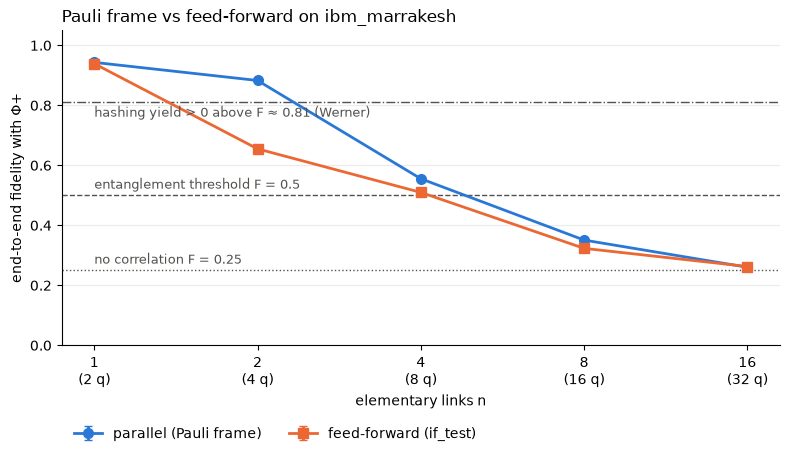

In [20]:
ff_result = ff_job.result()
ff_strings = [pub_strings(r) for r in ff_result]
ff_summaries, ff_counts = analyze_all(ff_strings, ff_labels, frame_correction=False)
print_fidelity_table(f"HARDWARE ({backend.name}), FEED-FORWARD (no post-processing correction)", ff_summaries)

ff_overhead, ff_t_shot = measured_overhead(ff_result, [ff_cycle["feedforward"][n] for (_, n, _) in ff_labels])
if ff_t_shot is not None:
    print(f"\nMeasured time per shot: feed-forward {ff_t_shot * 1e6:.1f} µs"
          + (f" vs Pauli-frame job {T_SHOT * 1e6:.1f} µs" if "T_SHOT" in globals() and T_SHOT else ""))
ff_rows = throughput_table(ff_summaries, ff_cycle, ff_overhead if ff_overhead is not None else (REP_DELAY or 0.0))
print_throughput(ff_rows)

if "hw_summaries" in globals():
    print("\nFeed-forward minus Pauli frame (parallel generation):")
    for n in sorted(ff_summaries["feedforward"]):
        if n in hw_summaries.get("parallel", {}):
            a, b = hw_summaries["parallel"][n], ff_summaries["feedforward"][n]
            d, se = b["F"] - a["F"], np.hypot(a["err"], b["err"])
            print(f"  {n:>2} links: ΔF = {d:+.3f} ({d / se:+.1f} SE)")
    fig = plot_fidelity({"parallel (Pauli frame)": hw_summaries["parallel"],
                         "feed-forward (if_test)": ff_summaries["feedforward"]},
                        f"Pauli frame vs feed-forward on {backend.name}")
    fig.savefig(RESULTS_DIR / f"{ff_stamp}_{backend.name}_repeater_ff_fidelity.png", dpi=150)

ff_record = {
    "experiment": "linear_repeater_feedforward",
    "timestamp_utc": ff_stamp,
    "backend": backend.name,
    "job_id": FF_JOB_ID,
    "pauli_frame_job_id": globals().get("JOB_ID"),
    "shots_per_circuit": SHOTS,
    "n_links": N_LINKS,
    "physical_qubit_line": LINE,
    "measured_time_per_shot_s": ff_t_shot,
    "overhead_per_shot_s": ff_overhead,
    "cycle_time_s_without_ff_latency": {str(n): t for n, t in ff_cycle["feedforward"].items()},
    "throughput": {str(n): r for n, r in ff_rows["feedforward"].items()},
    "counts": {str(n): c for n, c in ff_counts["feedforward"].items()},
    "summary": {str(n): s for n, s in ff_summaries["feedforward"].items()},
}
path = RESULTS_DIR / f"{ff_stamp}_{backend.name}_repeater_ff_results.json"
path.write_text(json.dumps(ff_record, indent=2, ensure_ascii=False), encoding="utf-8")
print("Saved", path)

## Interpreting the results

- **n = 1** is a single Bell pair, no swap: it sets the ceiling (gate + readout error of two qubits).
- **Fidelity vs n:** every extra level adds one ~2.7 µs measurement round during which all not-yet-swapped
  qubits and the two ends are stored, plus the gate and readout errors of the new qubits. Without purification,
  F decays towards 0.25; the last n with F > 0.5 (filled markers) is the longest chain that still delivers entanglement.
- **Throughput vs n:** the *pair* rate falls slowly (cycle time grows with log₂ n), but the *distillable* rate
  collapses as soon as F drops below ≈ 0.81, because hashing needs high-quality pairs. This is the core reason real
  repeaters need purification: without it, longer chains deliver pairs at almost the same rate but of no use.
- **Device vs protocol rate:** on this chip most of each shot is the wait between shots (reset/repetition delay),
  not the protocol. The protocol-limited rate is the figure that would carry over to a network whose nodes can reset
  quickly; the device rate is what this hardware actually delivered.
- **Sequential vs parallel generation:** a single shared source makes the cycle time grow linearly in n and keeps
  the first links stored longer; the difference shows how much a dedicated source per link is worth.
- **Missing from this emulation:** link generation never fails and there is no classical communication delay
  between nodes (only the on-chip measurement time). Both would lower the rates of a real network further.